# Lab 10: Independent RT-DETRv2 training

This notebook documents the local, from-scratch single-class detector pipeline. It uses the course F1/10 image set, a consecutive-frame block split to reduce temporal leakage, and the course-specified COCO RT-DETRv2-R18vd checkpoint. No teammate implementation or result is used.

In [1]:
from pathlib import Path
import json, sys, yaml, torch
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print('project:', ROOT)
print('torch:', torch.__version__)
print('cuda:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

project: <repository root>
torch: 2.6.0+cu124
cuda: True NVIDIA GeForce RTX 4060 Laptop GPU


## Dataset and leakage-resistant split

The 1,792 labels are pixel-space `(cx, cy, width, height)`. We hold out whole 50-frame temporal blocks instead of randomly mixing adjacent video frames across train and validation.

In [2]:
from training_data import DEFAULT_DATA_ROOT, block_split, load_dataset_index
paths, labels = load_dataset_index(DEFAULT_DATA_ROOT)
split = block_split(len(paths), validation_fraction=0.15, block_size=50, seed=6150)
assert not (set(split.train_indices) & set(split.validation_indices))
{'images': len(paths), 'label_shape': labels.shape, 'train': len(split.train_indices), 'validation': len(split.validation_indices), 'validation_blocks': split.validation_blocks}

{'images': 1792,
 'label_shape': (1792, 4),
 'train': 1542,
 'validation': 250,
 'validation_blocks': (5, 8, 14, 28, 32)}

## Pretrained initialization

All shape-compatible tensors are loaded. The eight one-class score-head tensors are initialized from COCO class index 2 (`car`); no randomly initialized classification head is needed.

In [3]:
from rtdetrv2_model import build_rtdetrv2
from training import DEFAULT_PRETRAINED, load_coco_pretrained_car_head
model = build_rtdetrv2()
load_report = load_coco_pretrained_car_head(model, DEFAULT_PRETRAINED)
result = load_report.to_dict()
result['parameter_count'] = sum(p.numel() for p in model.parameters())
result

{'exact_tensor_count': 527,
 'exact_parameter_fraction': 0.9999488756548006,
 'copied_class_heads': ('decoder.dec_score_head.0.bias',
  'decoder.dec_score_head.0.weight',
  'decoder.dec_score_head.1.bias',
  'decoder.dec_score_head.1.weight',
  'decoder.dec_score_head.2.bias',
  'decoder.dec_score_head.2.weight',
  'decoder.enc_score_head.bias',
  'decoder.enc_score_head.weight'),
 'missing_model_keys': (),
 'unused_checkpoint_keys': ('decoder.anchors',
  'decoder.denoising_class_embed.weight',
  'decoder.valid_mask'),
 'parameter_count': 20082516}

## Reproducible training configuration

Set `RUN_TRAINING=True` only when intentionally repeating the approximately 11-minute RTX 4060 run. The checked-in local artifacts below were produced with exactly this pipeline and configuration.

In [4]:
from training import TrainConfig, train
config = TrainConfig(output_dir=ROOT/'artifacts'/'training', epochs=12, batch_size=16, gradient_accumulation=1, learning_rate=1e-4, warmup_steps=200, num_workers=2, seed=6150, amp=True)
RUN_TRAINING = False
if RUN_TRAINING:
    summary = train(config)
else:
    print('Using completed local run. Set RUN_TRAINING=True to repeat it.')
config.to_dict()

Using completed local run. Set RUN_TRAINING=True to repeat it.


{'data_root': 'data/f110_dataset_20220209/f110_dataset_20220209',
 'pretrained_checkpoint': 'models/pretrained/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth',
 'output_dir': 'artifacts/training',
 'image_size': 640,
 'epochs': 12,
 'batch_size': 16,
 'gradient_accumulation': 1,
 'learning_rate': 0.0001,
 'weight_decay': 0.0001,
 'warmup_steps': 200,
 'clip_max_norm': 0.1,
 'validation_fraction': 0.15,
 'split_block_size': 50,
 'seed': 6150,
 'num_workers': 2,
 'amp': True,
 'ema_decay': 0.9998,
 'confidence_threshold': 0.5}

## Results

In [5]:
artifact_dir = ROOT/'artifacts'/'training'
summary = json.loads((artifact_dir/'summary.json').read_text())
history = yaml.safe_load((artifact_dir/'history.yaml').read_text())
assert len(history) == 12 and summary['final']['ap50'] == 1.0
{'selected_checkpoint_epoch': summary['selected_checkpoint_epoch'], 'final_train_loss': summary['final']['train_loss'], 'final_validation_loss': summary['final']['validation_loss'], 'final_ap50': summary['final']['ap50'], 'final_mean_iou': summary['final']['mean_iou'], 'final_accuracy_50': summary['final']['accuracy_50'], 'peak_cuda_memory_gb': summary['final']['peak_cuda_memory_gb']}

{'selected_checkpoint_epoch': 12,
 'final_train_loss': 1.1018743980675936,
 'final_validation_loss': 0.22794984467327595,
 'final_ap50': 1.0,
 'final_mean_iou': 0.9740407257080078,
 'final_accuracy_50': 1.0,
 'peak_cuda_memory_gb': 5.3663554191589355}

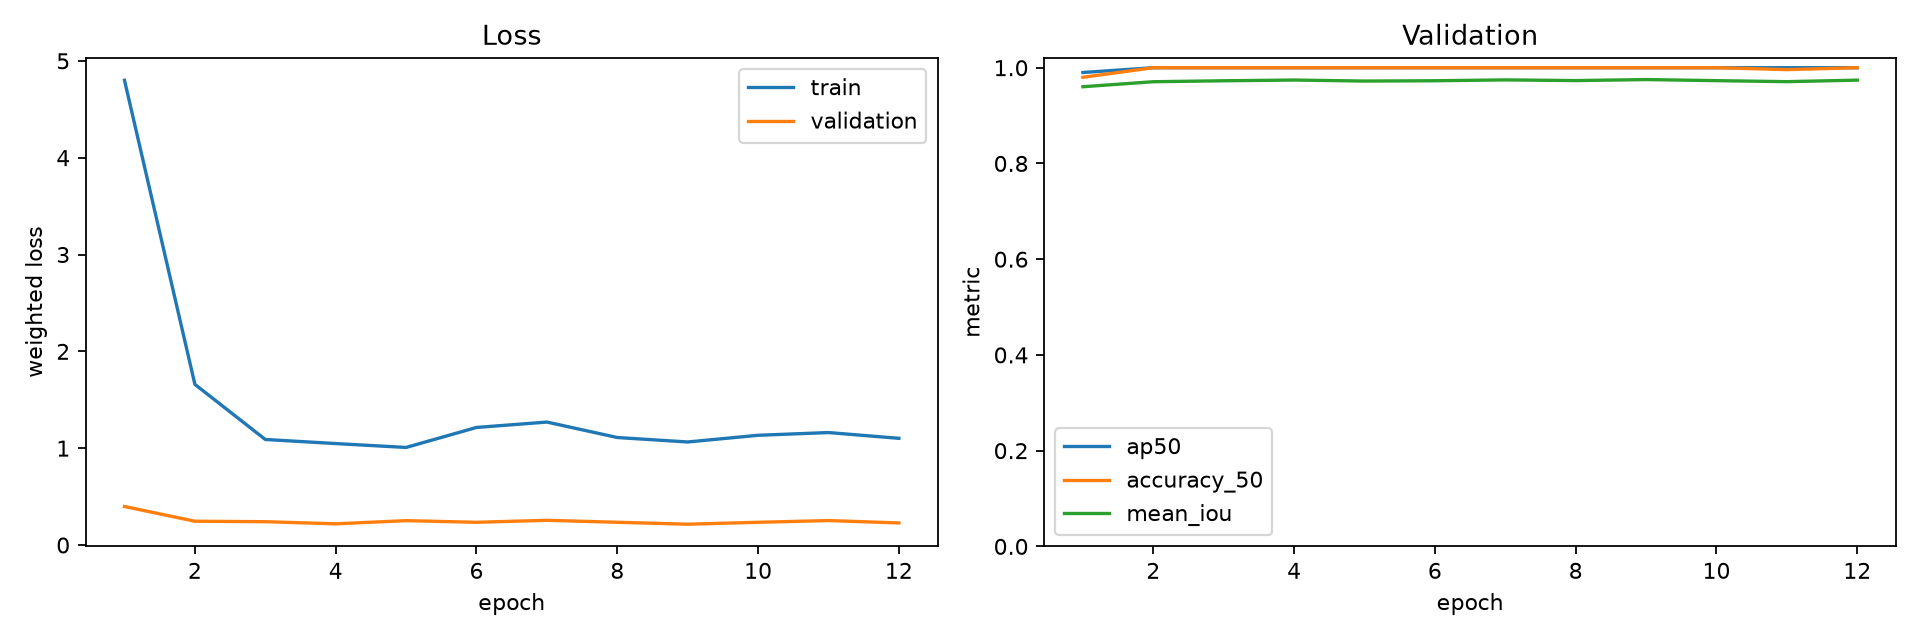

In [6]:
display(Image(filename=str(artifact_dir/'training_history.png')))

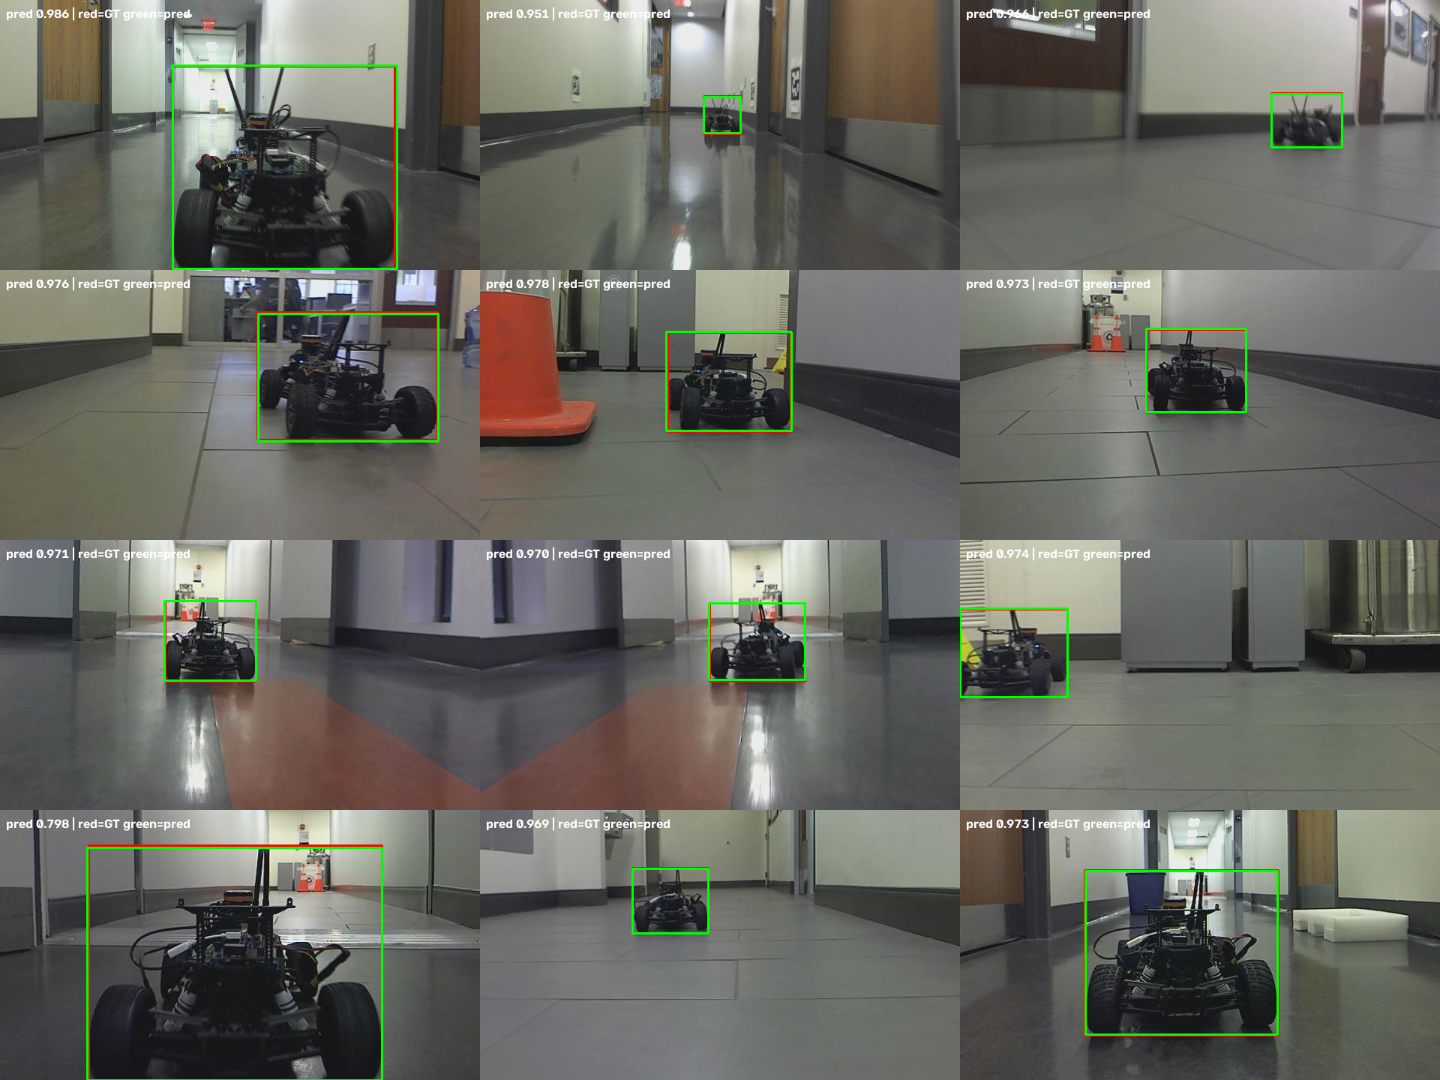

In [7]:
display(Image(filename=str(artifact_dir/'selected_validation_predictions.png')))

## Boundary of this software result

These are offline held-out results. Camera FPS, physical LiDAR-camera extrinsics, Jetson TensorRT timing, measured package distance, and real-car integration evidence remain explicitly pending hardware measurement.